## Environment Setup and Data Loading
Loading the Pakistan used car price dataset and verifying the environment is ready. A fixed random seed
is set for reproducibility throughout the project.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Reproducibility: fixed seed used throughout the project
RANDOM_STATE = 42

# Load the dataset — replace with your actual filename if different
df = pd.read_csv("../Dataset/used_cars_Pakistan.csv")

print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
df.head()

Rows: 86120
Columns: 9


,Unnamed: 0,make,model,city,year,mileage,Engine_displacement,Battery,Price_Rs
0,0,Suzuki,Alto,Lahore,2019,45744,660.0,NaN,3550000
1,1,Suzuki,Wagon,Lahore,2019,17583,660.0,NaN,3850000
2,2,Suzuki,Wagon,Lahore,2019,64085,660.0,NaN,3890000
3,3,Suzuki,Wagon,Lahore,2019,71281,660.0,NaN,3990000
4,4,Toyota,Aqua,Lahore,2020,19950,1500.0,NaN,3990000


## Data Structure
Checking column types and non-null counts. The dataset has 9 raw columns: 4 numeric, 3 categorical (text),
plus Battery which is mostly empty.

In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 86120 entries, 0 to 86119
Data columns (total 9 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Unnamed: 0           86120 non-null  int64  
 1   make                 86120 non-null  str    
 2   model                86120 non-null  str    
 3   city                 86120 non-null  str    
 4   year                 86120 non-null  int64  
 5   mileage              86120 non-null  int64  
 6   Engine_displacement  85931 non-null  float64
 7   Battery              189 non-null    float64
 8   Price_Rs             86120 non-null  int64  
dtypes: float64(2), int64(4), str(3)
memory usage: 5.9 MB


## Data Quality and Basic Statistics
Checking missing values, duplicate rows, and basic statistics to identify data quality issues before
modeling.

**Findings:** Engine_displacement has 189 missing values; Battery is populated for only 189 of 86,120 rows
(0.2%), suggesting it marks electric/hybrid vehicles specifically. Price_Rs has a minimum of
-2,147,483,648, exactly the minimum value for a 32-bit integer, indicating an integer overflow bug.
year ranges from 1944 to 2023, and Engine_displacement reaches an implausible 15,000cc, both suggesting
a small number of erroneous or extreme entries.

In [3]:
df.describe()

,Unnamed: 0,year,mileage,Engine_displacement,Battery,Price_Rs
count,86120.000000,86120.000000,86120.000000,85931.000000,189.000000,8.612000e+04
mean,43059.500000,2012.669995,88789.209963,1388.138146,119.653439,4.173561e+06
std,24860.846928,8.862183,87932.720095,766.087270,207.891986,9.717305e+06
min,0.000000,1944.000000,1.000000,0.000000,3.000000,-2.147484e+09
25%,21529.750000,2007.000000,31000.000000,1000.000000,60.000000,1.500000e+06
50%,43059.500000,2015.000000,78000.000000,1300.000000,80.000000,2.800000e+06
75%,64589.250000,2020.000000,121000.000000,1600.000000,101.000000,4.750000e+06
max,86119.000000,2023.000000,1000000.000000,15000.000000,2000.000000,3.015000e+08


## Investigating Data Quality Issues
Quantifying the scope of each quality issue found in the previous step: price overflow, suspicious years,
and engine displacement anomalies.

**Findings:** 1 row has a corrupted negative price (32-bit integer overflow) and 112 rows have
suspiciously low prices (<50,000 PKR), both likely errors. Years before 1990 account for 2,293 rows and
before 2000 for 7,400 rows (8.6%), but the year-by-year counts show a smooth, gradually increasing tail
rather than random spikes, suggesting these are genuine older vehicles still circulating in Pakistan's
used car market rather than data errors. For engine displacement, cross-checking against the Battery
column revealed that all 189 rows with Engine_displacement == NaN have a Battery value (confirming these
are genuine electric vehicles with no combustion engine), while the 2,993 rows with Engine_displacement
== 0 have no Battery value, indicating 0 is a placeholder for missing data on non-EV cars rather than a
real measurement. 173 rows have an implausible engine size above 5,000cc, likely data entry errors.

In [4]:
#checking any overflow issues in the Price_Rs column
print("Negative prices:", (df["Price_Rs"] < 0).sum())
print("Very low prices (under 50,000 PKR):", (df["Price_Rs"] < 50000).sum())
#checking suspicious year values in the Year column
print("Year < 1990:", (df["year"] < 1990).sum())
print("Year < 2000:", (df["year"] < 2000).sum())
#checking any extreme engine displacment
print("Engine_displacement > 5000:", (df["Engine_displacement"] > 5000).sum())
print("Engine_displacement == 0:", (df["Engine_displacement"] == 0).sum())

Negative prices: 1
Very low prices (under 50,000 PKR): 112
Year < 1990: 2293
Year < 2000: 7400
Engine_displacement > 5000: 173
Engine_displacement == 0: 2993


In [5]:
df["year"].value_counts().sort_index().head(20)

year
1944     2
1946     1
1950     2
1951     1
1952     6
1960     9
1961     5
1962     3
1963     4
1964     5
1965     6
1966     3
1967    10
1968     8
1969    16
1970     6
1971     5
1972     8
1973    17
1974    23
Name: count, dtype: int64

In [6]:
# How many rows have engine == 0 AND a battery value (likely real EVs)?
print("Engine 0 AND Battery not null:", ((df["Engine_displacement"] == 0) & (df["Battery"].notna())).sum())

# How many rows have engine == 0 but NO battery value (likely missing data, not EVs)?
print("Engine 0 AND Battery is null:", ((df["Engine_displacement"] == 0) & (df["Battery"].isna())).sum())

print("Battery not null AND Engine_displacement is NaN:", ((df["Battery"].notna()) & (df["Engine_displacement"].isna())).sum())

Engine 0 AND Battery not null: 0
Engine 0 AND Battery is null: 2993
Battery not null AND Engine_displacement is NaN: 189


## Investigating Low-Price Rows
Inspecting the 112 rows with Price_Rs under 50,000 PKR to check for a pattern before deciding how to
handle them.

**Findings:** 111 of the 112 rows have Price_Rs exactly equal to 0, spread across many different makes
(Suzuki, Toyota, Honda, Mercedes, KIA, Nissan, and others), ruling out a brand-specific scraping bug.
This indicates 0 is a placeholder for "price not listed," consistent with other placeholder values found
elsewhere in this dataset (e.g. Engine_displacement == 0). Since Price_Rs is the target variable, these
rows cannot be imputed like a missing feature, they must be dropped, along with the single row affected
by the integer overflow bug.

In [7]:
#checking if the prices < 50,000 are valid or not 
df[df["Price_Rs"] < 50000].sort_values("Price_Rs").head(20)

,Unnamed: 0,make,model,city,year,mileage,Engine_displacement,Battery,Price_Rs
785,785,Suzuki,Khyber,Karachi,1987,252858,1000.0,NaN,-2147483648
86,86,Haval,Jolion,Islamabad,2023,15,1500.0,NaN,0
123,123,Honda,N,Multan,2018,63000,660.0,NaN,0
197,197,Mitsubishi,EK,Multan,2009,90000,660.0,NaN,0
1011,1011,Suzuki,Alto,Lahore,2023,27,660.0,NaN,0
2565,2565,Toyota,Prado,Islamabad,2016,55000,2700.0,NaN,0
4008,4008,Honda,Vezel,Rawalpindi,2021,15000,1500.0,NaN,0
4009,4009,Toyota,Land,Islamabad,1986,100000,3500.0,NaN,0
4933,4933,Toyota,C-HR,Rawalpindi,2018,51350,1800.0,NaN,0
6413,6413,KIA,Sportage,Islamabad,2023,25,1999.0,NaN,0


In [8]:
#checking 20 lowest priced cars
df[df["Price_Rs"] < 50000]["make"].value_counts()

make
Toyota        49
Honda         12
Suzuki        10
Hyundai       10
Haval          5
Mercedes       4
Nissan         4
MG             3
Audi           3
Mazda          3
Mitsubishi     2
KIA            2
BAIC           2
Ford           1
BMW            1
Daihatsu       1
Name: count, dtype: int64

## Removing Invalid Target Rows
Dropping rows where Price_Rs is a placeholder (0) or corrupted (negative, from the integer overflow bug),
since the target variable cannot be imputed.

In [9]:
#for bad rows
bad_price_mask = df["Price_Rs"] < 50000
print("Rows to drop:", bad_price_mask.sum())

df = df[~bad_price_mask].reset_index(drop=True)
print("Rows remaining:", df.shape[0])

Rows to drop: 112
Rows remaining: 86008


In [10]:
df[df["Engine_displacement"] > 5000].sort_values("Engine_displacement", ascending=False).head(20)

,Unnamed: 0,make,model,city,year,mileage,Engine_displacement,Battery,Price_Rs
68000,68111,Toyota,Corolla,Lahore,2021,85000,15000.0,NaN,4150000
83102,83214,Honda,Civic,Bahawalpur,1997,200000,15000.0,NaN,1000000
58351,58455,Suzuki,Khyber,Islamabad,1998,5555,15000.0,NaN,500000
52856,52960,Honda,Civic,Sialkot,2005,216611,15000.0,NaN,1500000
25327,25419,Honda,Civic,Islamabad,1995,10000,15000.0,NaN,750000
63523,63631,Prince,Pearl,Multan,2022,7000,15000.0,NaN,1500000
56069,56173,Toyota,Corolla,Swat,2010,1,15000.0,NaN,3000000
21724,21816,Honda,Freed,Gujranwala,2014,85000,14983.0,NaN,4050000
78626,78738,Suzuki,Swift,Lahore,2012,220000,14000.0,NaN,1850000
71517,71629,Suzuki,Margalla,Charsadda,1994,90000,13000.0,NaN,570000


## Cleaning Engine Displacement
Converting invalid Engine_displacement values (0, used as a missing-data placeholder, and values above
5000cc, which are implausible for passenger cars) to NaN, so they can be properly imputed later rather
than treated as real measurements.

**Findings:** 3,166 values were converted (2,993 zeros + 173 extreme outliers), bringing total missing
Engine_displacement to 3,354 (3.9% of the remaining 86,008 rows). This count is one less than the expected
3,355 because one of the rows dropped earlier for an invalid price was itself a genuine electric vehicle
with an already-missing Engine_displacement value.

In [11]:
# Treat 0 and implausibly large engine values as missing, not real measurements
invalid_engine_mask = (df["Engine_displacement"] == 0) | (df["Engine_displacement"] > 5000)
print("Rows with invalid engine displacement:", invalid_engine_mask.sum())

df.loc[invalid_engine_mask, "Engine_displacement"] = np.nan
print("Total missing values in Engine_displacement after cleaning:", df["Engine_displacement"].isna().sum())

Rows with invalid engine displacement: 3166
Total missing values in Engine_displacement after cleaning: 3354


## Feature Engineering: is_electric
Creating a binary flag indicating whether a listing is an electric vehicle, based on whether Battery has
a recorded value.

**Finding:** 188 of 86,008 listings (0.2%) are electric vehicles.

In [12]:
# Making a new column (is_electric) to indicate whether the car is electric or not based on the Battery column
df["is_electric"] = df["Battery"].notna().astype(int)
print("Number of electric cars:", df["is_electric"].sum())

Number of electric cars: 188


## Feature Engineering: car_age
Creating car_age as a reference year (2024) minus the manufacturing year, since age is more directly
interpretable for pricing than raw year.

**Finding:** Ages range from 1 to 80 years (median 9), right-skewed as expected, with no negative values
confirming no data errors in this calculation.

In [13]:
#new column for car age
df["car_age"] = 2024 - df["year"]
df["car_age"].describe()

count    86008.000000
mean        11.338620
std          8.862557
min          1.000000
25%          4.000000
50%          9.000000
75%         17.000000
max         80.000000
Name: car_age, dtype: float64

In [14]:
#safety check for for any car ages equal to 0 (zero)
print("Rows with car_age == 0:", (df["car_age"] == 0).sum())

Rows with car_age == 0: 0


In [15]:
#new column for mileage per year
df["mileage_per_year"] = df["mileage"] / df["car_age"]
df["mileage_per_year"].describe()

count     86008.000000
mean       9110.357105
std        7385.237781
min           0.015873
25%        5000.000000
50%        8333.333333
75%       12000.000000
max      249999.750000
Name: mileage_per_year, dtype: float64

In [16]:
df.sort_values("mileage_per_year", ascending=False).head(10)

,Unnamed: 0,make,model,city,year,mileage,Engine_displacement,Battery,Price_Rs,is_electric,car_age,mileage_per_year
54960,55064,Suzuki,Cultus,Faisalabad,2020,999999,1000.0,NaN,2875000,0,4,249999.750000
49393,49495,Toyota,Coaster,Faisalabad,2023,234000,4000.0,NaN,12000000,0,1,234000.000000
44094,44192,Honda,BR-V,Sadiqabad,2021,580000,NaN,NaN,5200000,0,3,193333.333333
3444,3450,Mitsubishi,Minica,Lahore,2023,185000,660.0,NaN,2800000,0,1,185000.000000
24370,24462,Honda,City,Lahore,2019,900000,1500.0,NaN,4300000,0,5,180000.000000
49755,49857,Toyota,Corolla,Chishtian,2019,890000,1300.0,NaN,4450000,0,5,178000.000000
5367,5376,Honda,BR-V,Karachi,2019,880000,1500.0,NaN,4230000,0,5,176000.000000
78898,79010,Honda,BR-V,Faisalabad,2021,520000,1500.0,NaN,5400000,0,3,173333.333333
4204,4212,Toyota,Corolla,Wah cantt,2019,840000,1300.0,NaN,4485000,0,5,168000.000000
47830,47932,Suzuki,Mehran,Chowk munda,2018,1000000,NaN,NaN,1250000,0,6,166666.666667


In [17]:
#check the raw mileage column's distribution directly to decide a sensible cutoff
df["mileage"].describe()
print("\nMileage > 500,000:", (df["mileage"] > 500000).sum())
print("Mileage > 300,000:", (df["mileage"] > 300000).sum())


Mileage > 500,000: 494
Mileage > 300,000: 1243


In [18]:
print("mileage_per_year > 100,000:", (df["mileage_per_year"] > 100000).sum())
print("mileage_per_year > 50,000:", (df["mileage_per_year"] > 50000).sum())

mileage_per_year > 100,000: 67
mileage_per_year > 50,000: 238


In [19]:
# 1. Mask: rows where mileage_per_year is above 100,000
bad_mileage_mask = df["mileage_per_year"] > 100000

# 2. Check the count before changing anything
print("Rows to fix:", bad_mileage_mask.sum())

# 3. Blank out mileage for those rows only
df.loc[bad_mileage_mask, "mileage"] = np.nan

# 4. Recalculate mileage_per_year from the updated mileage
df["mileage_per_year"] = df["mileage"] / df["car_age"]

# 5. Verify
print("Missing mileage:", df["mileage"].isna().sum())
print("Rows still above 100,000:", (df["mileage_per_year"] > 100000).sum())

Rows to fix: 67
Missing mileage: 67
Rows still above 100,000: 0


In [20]:
df.columns.tolist()

['Unnamed: 0',
 'make',
 'model',
 'city',
 'year',
 'mileage',
 'Engine_displacement',
 'Battery',
 'Price_Rs',
 'is_electric',
 'car_age',
 'mileage_per_year']

## Duplicate Check
Checking for repeated listings by comparing every column except the row-number column (Unnamed: 0, which
is unique per row and would hide all duplicates).

**Findings:** 7,762 rows (9.02%) are exact repeats of an earlier row. Inspecting them shows the same
make, model, city, year, odometer reading, engine size and price, with some listings appearing up to three
times, which indicates the same advertisement was scraped multiple times rather than separate cars.
Keeping them would overweight those listings and could leak identical rows into both the training and
test sets, inflating performance.

In [21]:
cols_to_check = [c for c in df.columns if c != "Unnamed: 0"]

#count duplicate rows
dup_count = df.duplicated(subset = cols_to_check).sum()
print("Duplicate rows:", dup_count)
print(f"Share of dataset:{dup_count / df.shape[0]:.2%}")

df[df.duplicated(subset=cols_to_check, keep=False)].sort_values(
    ["make", "model", "year", "mileage"]
).head(10)

Duplicate rows: 7762
Share of dataset:9.02%


,Unnamed: 0,make,model,city,year,mileage,Engine_displacement,Battery,Price_Rs,is_electric,car_age,mileage_per_year
14294,14335,Audi,A3,Gujrat,2014,98000.0,1400.0,NaN,6300000,0,10,9800.000000
32564,32658,Audi,A3,Gujrat,2014,98000.0,1400.0,NaN,6300000,0,10,9800.000000
60052,60156,Audi,A3,Gujrat,2014,98000.0,1400.0,NaN,6300000,0,10,9800.000000
1082,1087,Audi,A3,Lahore,2015,45954.0,1800.0,NaN,6850000,0,9,5106.000000
1582,1587,Audi,A3,Lahore,2015,45954.0,1800.0,NaN,6850000,0,9,5106.000000
17717,17780,Audi,A3,Islamabad,2015,72000.0,1800.0,NaN,6500000,0,9,8000.000000
49251,49353,Audi,A3,Islamabad,2015,72000.0,1800.0,NaN,6500000,0,9,8000.000000
11241,11268,Audi,A3,Lahore,2015,104000.0,1800.0,NaN,6900000,0,9,11555.555556
23627,23719,Audi,A3,Lahore,2015,104000.0,1800.0,NaN,6900000,0,9,11555.555556
6258,6267,Audi,A3,Lahore,2015,125000.0,1800.0,NaN,6700000,0,9,13888.888889


## Removing Duplicate Listings
Dropping repeated rows (keeping the first occurrence) so each listing is counted once, then resetting the
index.

**Result:** 86,008 rows reduced to 78,246 (7,762 removed), with 0 duplicates remaining. Removing duplicates
before the train/test split also prevents identical listings from appearing in both sets.

In [22]:
rows_before = df.shape[0]

#drop duplicate rows
df = df.drop_duplicates(subset = cols_to_check, keep = "first").reset_index(drop = True)

print("Rows before:", rows_before)
print("Rows after:", df.shape[0])
print("Duplicates remaining:", df.duplicated(subset = cols_to_check).sum())

Rows before: 86008
Rows after: 78246
Duplicates remaining: 0


In [23]:
df["Price_Rs"].describe()

count    7.824600e+04
mean     3.919668e+06
std      5.841746e+06
min      1.129990e+05
25%      1.450000e+06
50%      2.680000e+06
75%      4.500000e+06
max      3.015000e+08
Name: Price_Rs, dtype: float64

In [24]:
# 20 cheapest listings remaining in the data
df.sort_values("Price_Rs").head(20)

,Unnamed: 0,make,model,city,year,mileage,Engine_displacement,Battery,Price_Rs,is_electric,car_age,mileage_per_year
135,144,Suzuki,Mehran,Rawalpindi,2016,65000.0,796.0,NaN,112999,0,8,8125.000000
375,435,Toyota,Corolla,Kohat,2000,198000.0,1500.0,NaN,117000,0,24,8250.000000
58676,66027,Suzuki,FX,Sadiqabad,1987,1000000.0,800.0,NaN,120000,0,37,27027.027027
937,1148,FAW,X-PV,Haripur,2016,50000.0,1000.0,NaN,120000,0,8,6250.000000
29910,35375,Suzuki,FX,Karachi,1985,175000.0,800.0,NaN,125000,0,39,4487.179487
26401,31484,Daihatsu,Charade,Karachi,1984,9999.0,NaN,NaN,130000,0,40,249.975000
68369,76000,Suzuki,FX,Karachi,1988,65000.0,800.0,NaN,130000,0,36,1805.555556
13953,17050,Suzuki,FX,Karachi,1987,100000.0,800.0,NaN,135000,0,37,2702.702703
28959,34326,Suzuki,FX,Karachi,1982,100000.0,800.0,NaN,145000,0,42,2380.952381
7230,9214,Suzuki,FX,Karachi,1985,999.0,800.0,NaN,150000,0,39,25.615385


In [25]:
# How many listings fall under each price threshold
for threshold in [200000, 300000, 500000]:
    count = (df["Price_Rs"] < threshold).sum()
    print(f"Price under {threshold:,}: {count}")

Price under 200,000: 88
Price under 300,000: 568
Price under 500,000: 2498


In [26]:
# Recent cars (2005 or newer) priced under 500,000 PKR
recent_cheap_mask = (df["year"] >= 2005) & (df["Price_Rs"] < 500000)
print("Recent cars under 500,000 PKR:", recent_cheap_mask.sum())

# The 20 cheapest of them
df[recent_cheap_mask].sort_values("Price_Rs").head(20)

Recent cars under 500,000 PKR: 165


,Unnamed: 0,make,model,city,year,mileage,Engine_displacement,Battery,Price_Rs,is_electric,car_age,mileage_per_year
135,144,Suzuki,Mehran,Rawalpindi,2016,65000.0,796.0,NaN,112999,0,8,8125.000000
937,1148,FAW,X-PV,Haripur,2016,50000.0,1000.0,NaN,120000,0,8,6250.000000
13548,16582,Changan,Karvaan,Rawalpindi,2019,46772.0,1000.0,NaN,170000,0,5,9354.400000
296,335,Mitsubishi,EK,Multan,2009,90000.0,660.0,NaN,200000,0,15,6000.000000
987,1227,Suzuki,Alto,Rawalpindi,2021,44000.0,660.0,NaN,229000,0,3,14666.666667
79,82,Honda,Civic,Faisalabad,2011,148000.0,1800.0,NaN,275000,0,13,11384.615385
20051,24289,Toyota,Fortuner,Karachi,2022,900.0,2800.0,NaN,280000,0,2,450.000000
44605,51180,Suzuki,Ravi,Lahore,2014,100000.0,800.0,NaN,300000,0,10,10000.000000
45406,52033,Sogo,Pickup,Karachi,2006,90000.0,800.0,NaN,300000,0,18,5000.000000
54490,61606,Haval,H6,Islamabad,2023,20.0,1500.0,NaN,300000,0,1,20.000000


## Removing Implausibly Cheap Recent Listings
Dropping listings from 2015 or later priced under 500,000 PKR. Recent cars at these prices (for example a
2023 Toyota Fortuner at 300,000 with 25 km on the odometer) are unlikely to be full sale prices and may
reflect down payments or installment amounts. Older cheap cars were kept, since low prices are realistic for
them.

**Result:** 24 rows removed (0.03%), leaving 78,222 rows.

In [27]:
rows_before = df.shape[0]

# Recent cars (2015 or newer) priced under 500,000 PKR
cheap_recent_mask = (df["year"] >= 2015) & (df["Price_Rs"] < 500000)
print("Rows to drop:", cheap_recent_mask.sum())

# Keep everything that does NOT match, then renumber the rows
df = df[~cheap_recent_mask].reset_index(drop=True)

print("Rows before:", rows_before)
print("Rows after:", df.shape[0])
print("Rows still matching:", ((df["year"] >= 2015) & (df["Price_Rs"] < 500000)).sum())   # expect 0

Rows to drop: 24
Rows before: 78246
Rows after: 78222
Rows still matching: 0


## Exploratory Data Analysis (EDA)
Before building any model, we look at the data to understand the target (`Price_Rs`), the feature distributions, and how the features relate to price. Figures are saved to `Report/figures/` so we can reuse them in the report and slides.

In [28]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 100

# Folder for report figures (notebook lives in Code/, so go one level up)
FIG_DIR = os.path.join("..", "Report", "figures")
os.makedirs(FIG_DIR, exist_ok=True)

def save_fig(name):
    plt.savefig(os.path.join(FIG_DIR, name), dpi=200, bbox_inches="tight")

# Drop the leftover index column
df = df.drop(columns=["Unnamed: 0"], errors="ignore")
print("Shape after dropping Unnamed: 0:", df.shape)

# Column names used in EDA. Adjust here if any name differs.
TARGET = "Price_Rs"
print("\nActual columns in df:")
print(df.columns.tolist())
print("\nDtypes:")
print(df.dtypes)

Shape after dropping Unnamed: 0: (78222, 11)

Actual columns in df:
['make', 'model', 'city', 'year', 'mileage', 'Engine_displacement', 'Battery', 'Price_Rs', 'is_electric', 'car_age', 'mileage_per_year']

Dtypes:
make                       str
model                      str
city                       str
year                     int64
mileage                float64
Engine_displacement    float64
Battery                float64
Price_Rs                 int64
is_electric              int64
car_age                  int64
mileage_per_year       float64
dtype: object


### Second cleaning pass (based on Batch E)
EDA showed several data-entry problems. Rows with an impossible *price* or an impossible make/model/year are dropped. Impossible *feature* values (placeholder mileage, tiny engines) are set to NaN and imputed later using training data only. EV engine size and non-EV battery size are set to 0 because those components genuinely do not exist.

In [29]:
# ---------- Second cleaning pass ----------
n_start = len(df)
print("Rows at start:", f"{n_start:,}")

# 1) Price far from peers (same make/model/year, groups of 5+ listings) -> DROP
grp = df.groupby(["make", "model", "year"])[TARGET]
peer_median = grp.transform("median")
peer_count = grp.transform("count")
ratio = df[TARGET] / peer_median
bad_price = (peer_count >= 5) & ((ratio > 5) | (ratio < 0.2))
print(f"\n1) Price > 5x or < 0.2x peer median: {bad_price.sum()} rows dropped")
print(df.loc[bad_price, ["make", "model", "year", TARGET]].assign(peer_median=peer_median[bad_price]).head(8).to_string())
df = df.loc[~bad_price].copy()

# 2) Impossible make/model/year (model did not exist yet) -> DROP
# (first_year values are from general knowledge: spot-check a couple before the viva)
first_year = [
    ("DFSK", None, 2003),
    ("Volkswagen", "Golf", 1974),
    ("Opel", "Corsa", 1982),
    ("Mazda", "626", 1978),
    ("Mitsubishi", "Pajero", 1982),
    ("Toyota", "Will", 2000),
    ("Jeep", "Wrangler", 1986),
    ("Jeep", "Cherokee", 1974),
    ("Toyota", "Corolla", 1966),
    ("Daewoo", "Racer", 1986),
]
impossible = pd.Series(False, index=df.index)
for mk, md, yr in first_year:
    m = (df["make"] == mk) & (df["year"] < yr)
    if md is not None:
        m &= (df["model"] == md)
    impossible |= m
print(f"\n2) Impossible make/model/year: {impossible.sum()} rows dropped")
print(df.loc[impossible, ["make", "model", "year", TARGET]].to_string())
df = df.loc[~impossible].copy()

# 3) Mileage problems -> NaN (imputed after the split)
placeholders = [123456, 12345, 111111]
m_ph = df["mileage"].isin(placeholders)
m_huge = df["mileage"] >= 500_000
m_low = (df["mileage"] <= 100) & (df["car_age"] >= 3)
print(f"\n3) Mileage set to NaN: placeholders={m_ph.sum()}, >=500k={m_huge.sum()}, "
      f"<=100 km on cars aged 3+={m_low.sum()}, total={(m_ph | m_huge | m_low).sum()}")
df.loc[m_ph | m_huge | m_low, "mileage"] = np.nan

# 4) Unrealistic km per year -> NaN (same formula as before: mileage / car_age)
df["mileage_per_year"] = df["mileage"] / df["car_age"]
m_kmyr = df["mileage_per_year"] > 50_000
print(f"4) Rows above 50,000 km/year set to NaN: {m_kmyr.sum()}")
df.loc[m_kmyr, "mileage"] = np.nan
df["mileage_per_year"] = df["mileage"] / df["car_age"]

# 5) Engine below 500 cc -> NaN; EV engine -> 0; Battery for non-EV -> 0
m_eng = df["Engine_displacement"] < 500
print(f"5) Engine < 500 cc set to NaN: {m_eng.sum()}")
df.loc[m_eng, "Engine_displacement"] = np.nan

ev_no_engine = (df["is_electric"] == 1) & df["Engine_displacement"].isna()
print(f"   EV rows with engine set to 0: {ev_no_engine.sum()}")
df.loc[ev_no_engine, "Engine_displacement"] = 0
print("   Non-EV rows that had a Battery value (should be 0):",
      df.loc[df["is_electric"] == 0, "Battery"].notna().sum())
df["Battery"] = df["Battery"].fillna(0)

df = df.reset_index(drop=True)

# Summary
print(f"\nRows: {n_start:,} -> {len(df):,}  (dropped {n_start - len(df)})")
print("\nMissing values now:")
print(df.isna().sum()[df.isna().sum() > 0].to_string())
print("\nPrice: min", f"{df[TARGET].min():,}", "| max", f"{df[TARGET].max():,}")
print(df[["mileage", "mileage_per_year", "Engine_displacement"]].describe().T.round(1).to_string())

Rows at start: 78,222

1) Price > 5x or < 0.2x peer median: 282 rows dropped
         make     model  year   Price_Rs  peer_median
9      Toyota  Fortuner  2022    1095000   18500000.0
39   Mercedes      Benz  2020     850000   30000000.0
79      Honda     Civic  2011     275000    2450000.0
163     Haval    Jolion  2023    1450000    8800000.0
185    Toyota     Prado  1996   27500000    4500000.0
283    Toyota     Hilux  2021    2350000   12600000.0
299     Honda     Civic  2014  301500000    3550000.0
349     Haval        H6  2023    1040000   12350000.0

2) Impossible make/model/year: 21 rows dropped
             make     model  year  Price_Rs
16658      Toyota   Corolla  1960   1000000
22093        Opel     Corsa  1966   1240000
25625        Jeep  Wrangler  1982   1100000
28551  Volkswagen      Golf  1966   1200000
32065        Jeep  Wrangler  1979   1600000
41736  Mitsubishi    Pajero  1965    750000
43019        DFSK       C37  1967   1300000
50016       Mazda       626  1977    

### A. Target Variable: Price Distribution
Price is what we want to predict, so we start there. We look at its raw distribution, its log-transformed distribution (car prices are usually right-skewed), and the most and least expensive listings to check they are plausible.

Price summary (Rs):
count         77,919
mean       3,906,048
std        5,673,617
min          120,000
25%        1,450,000
50%        2,690,000
75%        4,500,000
max      170,000,000
Name: Price_Rs, dtype: str

Skewness (raw price):      9.22
Skewness (log1p price):    0.05

Price percentiles (Rs):
0.010       325,000
0.050       600,000
0.250     1,450,000
0.500     2,690,000
0.750     4,500,000
0.950     9,500,000
0.990    24,000,000
0.999    87,500,000
Name: Price_Rs, dtype: str


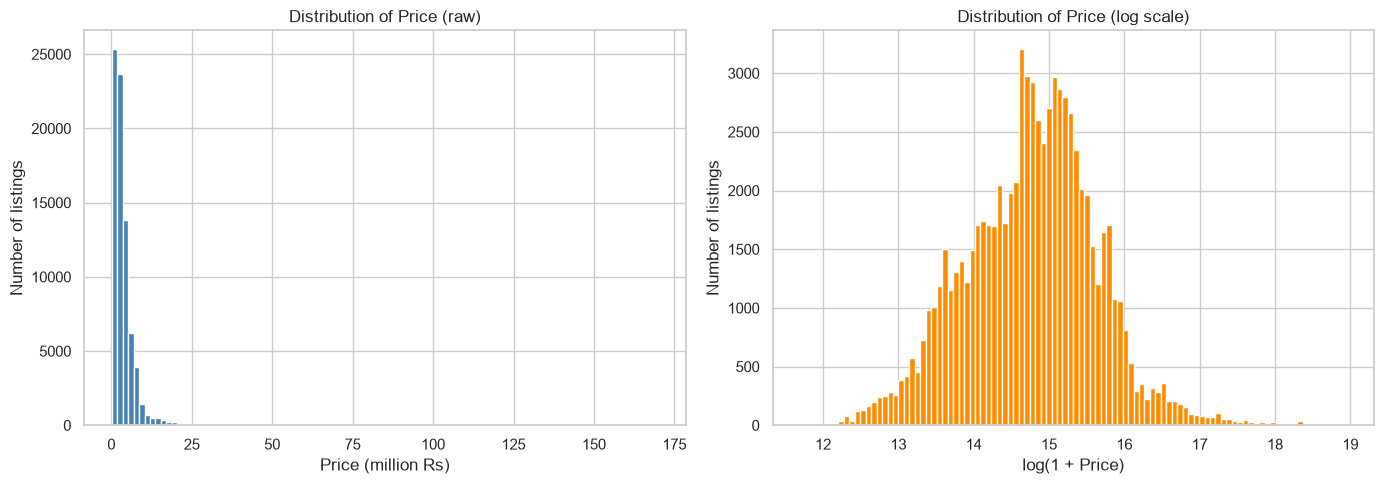


Top 15 most expensive listings:
          make        model  year  mileage  Engine_displacement       city   Price_Rs
10731    Lexus           LX  2022    335.0               3400.0    Karachi  170000000
5702     Lexus           LX  2022    500.0               3400.0     Lahore  165000000
18559  Bentley  Continental  2018  25000.0                  NaN     Lahore  155000000
41606   Toyota         Land  2023  30000.0               3500.0  Islamabad  150000000
32799    Lexus           LX  2021      NaN                  NaN    Karachi  135000000
9721     Lexus           LX  2021      NaN                  NaN    Karachi  120000000
17748   Toyota         Land  2022    999.0               3500.0  Islamabad  120000000
49446  Bentley     Mulsanne  2013  30000.0                  NaN  Islamabad  120000000
9522     Lexus           LX  2021      NaN                  NaN  Islamabad  110000000
27215      BMW            7  2022     65.0                  0.0     Lahore  110000000
44427      BMW       

In [30]:
# ---------- Batch A: Target variable ----------
price = df[TARGET]

print("Price summary (Rs):")
print(price.describe().apply(lambda x: f"{x:,.0f}"))
print(f"\nSkewness (raw price):      {price.skew():.2f}")
print(f"Skewness (log1p price):    {np.log1p(price).skew():.2f}")

print("\nPrice percentiles (Rs):")
print(price.quantile([0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99, 0.999]).apply(lambda x: f"{x:,.0f}"))

# Raw and log price histograms side by side
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(price / 1e6, bins=100, color="steelblue", edgecolor="white")
axes[0].set_title("Distribution of Price (raw)")
axes[0].set_xlabel("Price (million Rs)")
axes[0].set_ylabel("Number of listings")

axes[1].hist(np.log1p(price), bins=100, color="darkorange", edgecolor="white")
axes[1].set_title("Distribution of Price (log scale)")
axes[1].set_xlabel("log(1 + Price)")
axes[1].set_ylabel("Number of listings")

plt.tight_layout()
save_fig("A_price_distribution.png")
plt.show()

# Most expensive and cheapest listings
show_cols = [c for c in ["make", "model", "year", "mileage", "Engine_displacement", "city", TARGET] if c in df.columns]

print("\nTop 15 most expensive listings:")
print(df.nlargest(15, TARGET)[show_cols].to_string())

print("\n15 cheapest listings:")
print(df.nsmallest(15, TARGET)[show_cols].to_string())

### B. Numeric Feature Distributions and Categorical Cardinality
Histograms show the shape of each numeric feature and box plots highlight outliers. We also count how many unique values the categorical columns (`make`, `model`, `city`) have, since this decides how we encode them later.

Numeric columns used: ['year', 'car_age', 'mileage', 'mileage_per_year', 'Engine_displacement']

Summary statistics:
                       count      mean       std     min       25%      50%       75%       max
year                 77919.0   2012.33      8.92  1944.0   2007.00   2015.0    2019.0    2023.0
car_age              77919.0     11.67      8.92     1.0      5.00      9.0      17.0      80.0
mileage              74394.0  87589.28  66951.07     1.0  36000.00  80000.0  121000.0  499999.0
mileage_per_year     74394.0   9056.67   5601.74     0.5   5277.78   8500.0   12000.0   50000.0
Engine_displacement  74897.0   1398.54    649.49     0.0   1000.00   1300.0    1600.0    5000.0

Missing values in numeric columns:
year                      0
car_age                   0
mileage                3525
mileage_per_year       3525
Engine_displacement    3022
dtype: int64


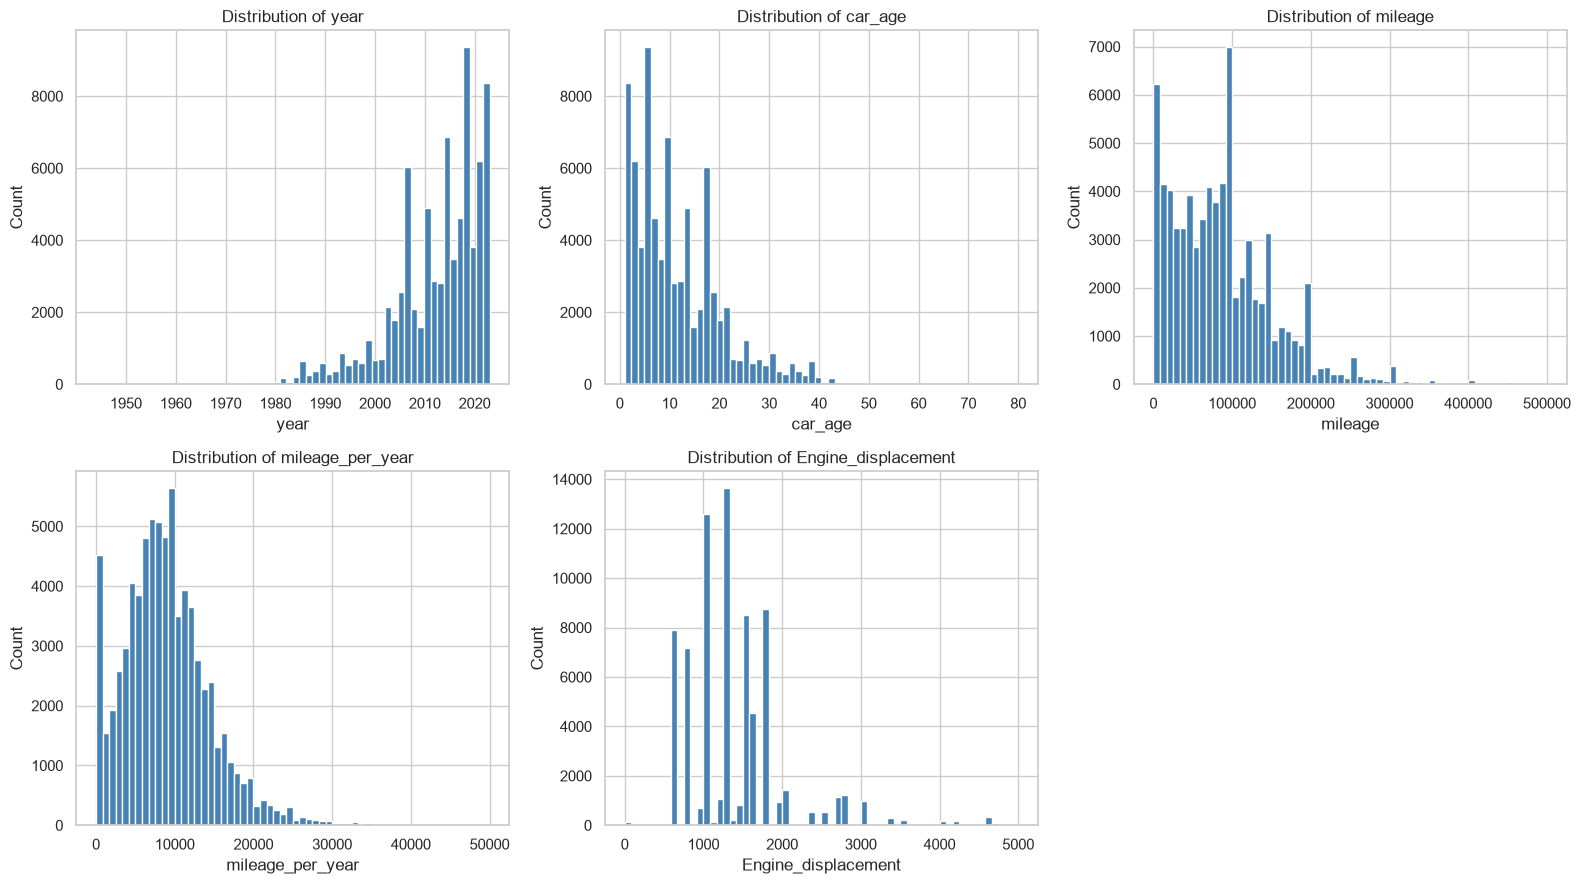

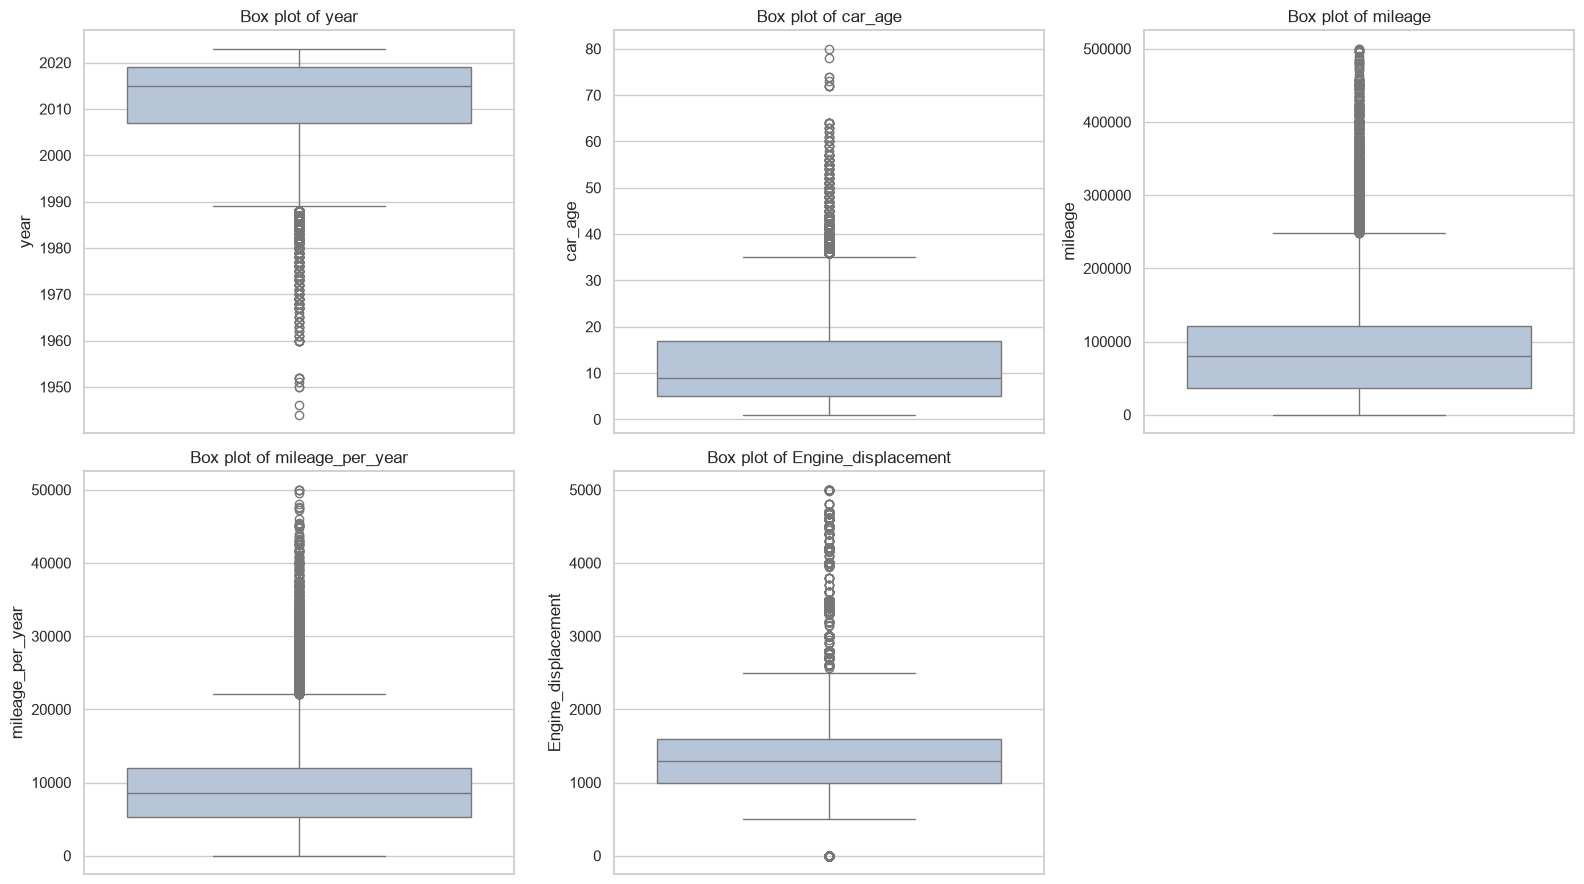


Number of unique values:
  make         71
  model       435
  city        320

Models with fewer than 10 listings: 223 of 435


In [31]:
# ---------- Batch B: Numeric features + categorical cardinality ----------
NUM_COLS = [c for c in ["year", "car_age", "mileage", "mileage_per_year", "Engine_displacement"] if c in df.columns]
CAT_COLS = [c for c in ["make", "model", "city"] if c in df.columns]

print("Numeric columns used:", NUM_COLS)
print("\nSummary statistics:")
print(df[NUM_COLS].describe().T.round(2).to_string())

print("\nMissing values in numeric columns:")
print(df[NUM_COLS].isna().sum())

# Histograms
n = len(NUM_COLS)
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()
for ax, col in zip(axes, NUM_COLS):
    ax.hist(df[col].dropna(), bins=60, color="steelblue", edgecolor="white")
    ax.set_title(f"Distribution of {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Count")
for ax in axes[n:]:
    ax.axis("off")
plt.tight_layout()
save_fig("B_numeric_histograms.png")
plt.show()

# Box plots
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()
for ax, col in zip(axes, NUM_COLS):
    sns.boxplot(y=df[col], ax=ax, color="lightsteelblue")
    ax.set_title(f"Box plot of {col}")
for ax in axes[n:]:
    ax.axis("off")
plt.tight_layout()
save_fig("B_numeric_boxplots.png")
plt.show()

# Categorical cardinality
print("\nNumber of unique values:")
for col in CAT_COLS:
    print(f"  {col:<8} {df[col].nunique():>6,}")

print("\nModels with fewer than 10 listings:",
      (df["model"].value_counts() < 10).sum(), "of", df["model"].nunique())

### C. Relationships Between Key Features and Price
Here we compare price across makes, car ages, and electric vs non-electric cars. We use the median rather than the mean because price is right-skewed and a few very expensive cars would distort the mean.

Top 15 makes by number of listings:
make
Toyota        24983
Suzuki        22460
Honda         16326
Daihatsu       3200
KIA            1722
Nissan         1565
Hyundai        1451
Mitsubishi     1089
Changan         936
Mercedes        604
MG              511
FAW             278
Audi            270
Proton          244
DFSK            228


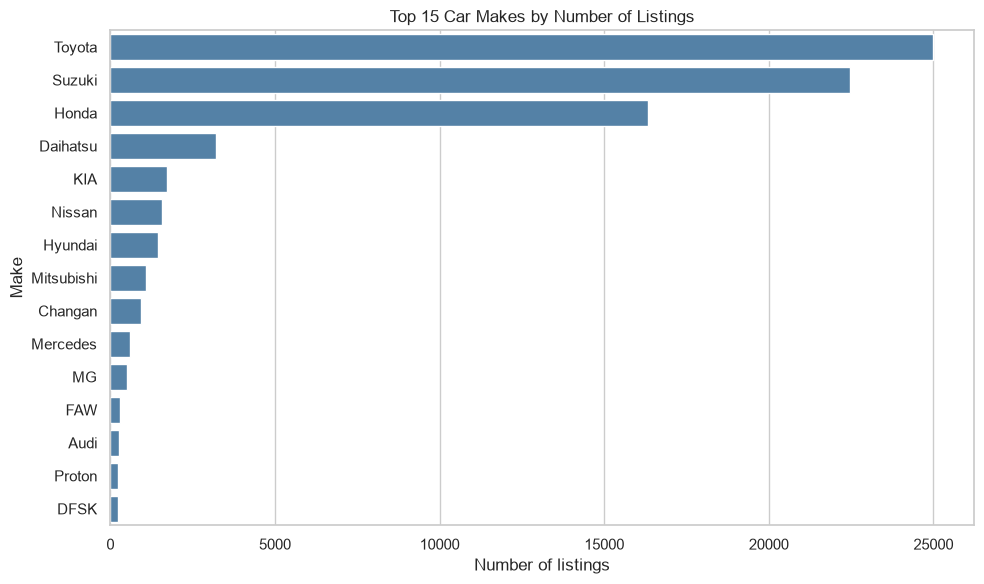


Makes with >= 100 listings: 23
Top 10 by median price (Rs):
make
Audi        12,000,000
Lexus       10,500,000
Haval       10,300,000
MG           7,250,000
Peugeot      7,200,000
KIA          7,000,000
Hyundai      6,275,000
DFSK         5,797,500
Mercedes     5,200,000
BMW          5,000,000
Bottom 10 by median price (Rs):
make
Honda         3,450,000
Mazda         2,400,000
Nissan        2,240,000
Daihatsu      1,785,000
Mitsubishi    1,680,000
Jeep          1,600,000
Prince        1,400,000
Suzuki        1,320,000
FAW           1,262,500
Chevrolet       875,000


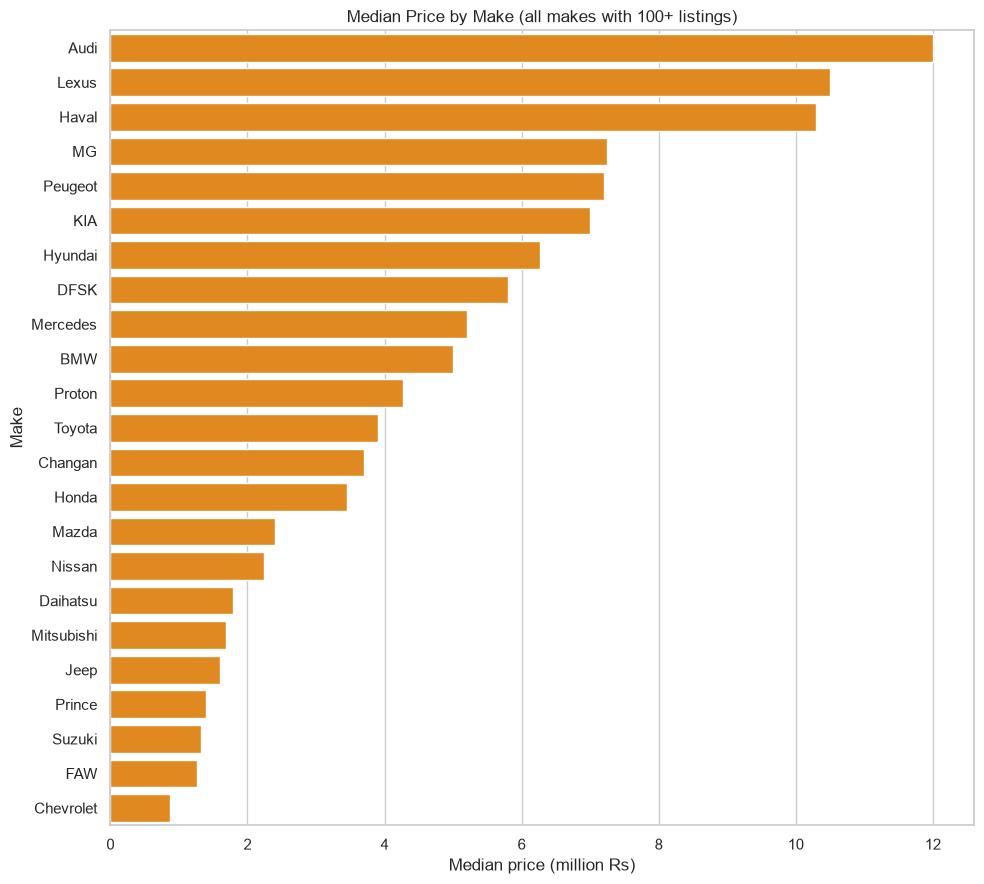


Median price by car age (first 15 ages):
 car_age    median  count
       1 7,700,000   2514
       2 5,350,000   5837
       3 4,985,000   6200
       4 4,350,000   3804
       5 4,050,000   4015
       6 4,000,000   5340
       7 3,700,000   4615
       8 3,279,999   3483
       9 3,050,000   3556
      10 2,762,500   3302
      11 2,575,000   2807
      12 2,350,000   2872
      13 2,250,000   2589
      14 2,150,000   2293
      15 2,000,000   1585


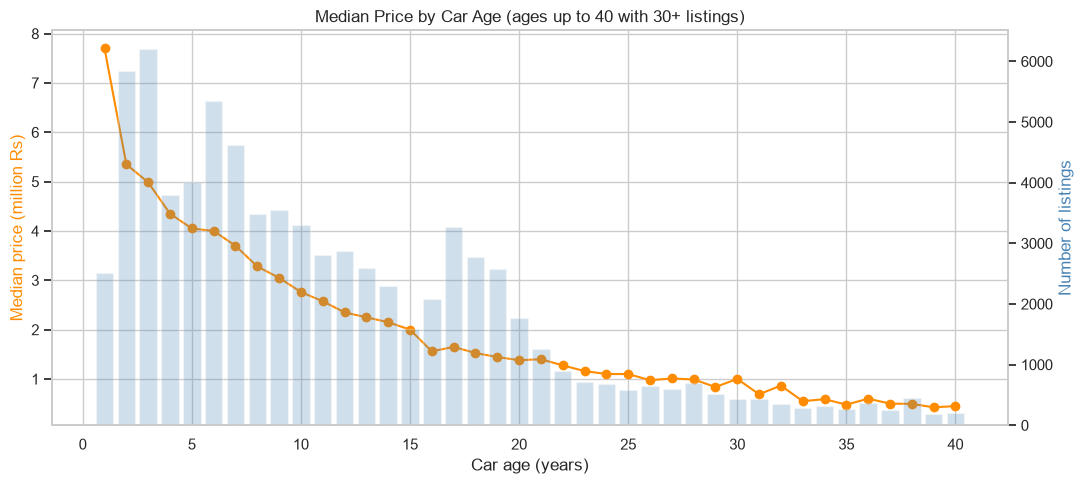


Electric vs non-electric:
              count      median        mean      min          max
is_electric                                                      
0            77,792   2,680,000   3,854,643  120,000  170,000,000
1               127  30,000,000  35,393,346  540,000  110,000,000


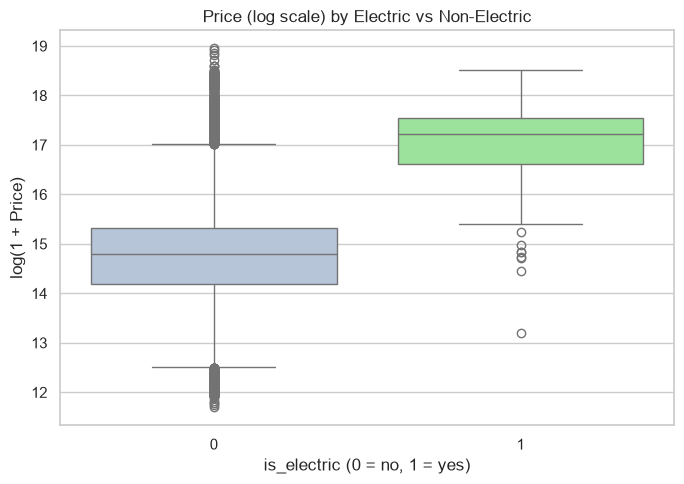

In [32]:
# ---------- Batch C: Group relationships ----------
# --- Top makes by number of listings ---
top_makes = df["make"].value_counts().head(15)
print("Top 15 makes by number of listings:")
print(top_makes.to_string())

fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(x=top_makes.values, y=top_makes.index, color="steelblue", ax=ax)
ax.set_title("Top 15 Car Makes by Number of Listings")
ax.set_xlabel("Number of listings")
ax.set_ylabel("Make")
plt.tight_layout()
save_fig("C_top_makes_count.png")
plt.show()

# --- Median price by make (only makes with at least 100 listings) ---
make_counts = df["make"].value_counts()
common_makes = make_counts[make_counts >= 100].index
med_make = (df[df["make"].isin(common_makes)]
            .groupby("make")[TARGET].median()
            .sort_values(ascending=False))

print(f"\nMakes with >= 100 listings: {len(common_makes)}")
print("Top 10 by median price (Rs):")
print(med_make.head(10).apply(lambda x: f"{x:,.0f}").to_string())
print("Bottom 10 by median price (Rs):")
print(med_make.tail(10).apply(lambda x: f"{x:,.0f}").to_string())

fig, ax = plt.subplots(figsize=(10, 9))
plot_data = med_make / 1e6
sns.barplot(x=plot_data.values, y=plot_data.index, color="darkorange", ax=ax)
ax.set_title("Median Price by Make (all makes with 100+ listings)")
ax.set_xlabel("Median price (million Rs)")
ax.set_ylabel("Make")
plt.tight_layout()
save_fig("C_median_price_by_make.png")
plt.show()

# --- Median price by car age ---
age_stats = (df.groupby("car_age")[TARGET]
               .agg(median="median", count="count")
               .reset_index())
age_plot = age_stats[(age_stats["car_age"] <= 40) & (age_stats["count"] >= 30)]

print("\nMedian price by car age (first 15 ages):")
print(age_stats.head(15).assign(median=lambda d: d["median"].map("{:,.0f}".format)).to_string(index=False))

fig, ax1 = plt.subplots(figsize=(11, 5))
ax1.plot(age_plot["car_age"], age_plot["median"] / 1e6, marker="o", color="darkorange")
ax1.set_xlabel("Car age (years)")
ax1.set_ylabel("Median price (million Rs)", color="darkorange")
ax1.set_title("Median Price by Car Age (ages up to 40 with 30+ listings)")
ax2 = ax1.twinx()
ax2.bar(age_plot["car_age"], age_plot["count"], alpha=0.25, color="steelblue")
ax2.set_ylabel("Number of listings", color="steelblue")
ax2.grid(False)
plt.tight_layout()
save_fig("C_median_price_by_age.png")
plt.show()

# --- Electric vs non-electric ---
print("\nElectric vs non-electric:")
ev_summary = df.groupby("is_electric")[TARGET].agg(["count", "median", "mean", "min", "max"])
print(ev_summary.map(lambda x: f"{x:,.0f}").to_string())

fig, ax = plt.subplots(figsize=(7, 5))
sns.boxplot(x=df["is_electric"], y=np.log1p(df[TARGET]), hue=df["is_electric"],
            palette=["lightsteelblue", "lightgreen"], legend=False, ax=ax)
ax.set_title("Price (log scale) by Electric vs Non-Electric")
ax.set_xlabel("is_electric (0 = no, 1 = yes)")
ax.set_ylabel("log(1 + Price)")
plt.tight_layout()
save_fig("C_electric_vs_nonelectric.png")
plt.show()

### D. Correlation Analysis
The correlation heatmap shows how strongly numeric features move together, and with price. Pearson measures linear relationships; Spearman measures monotonic (rank-based) ones and is less affected by outliers. We use `log_price` alongside the raw price because it is closer to normally distributed.

Pearson correlation with Price_Rs:
log_price              0.690
Engine_displacement    0.498
year                   0.305
is_electric            0.224
Battery                0.106
mileage_per_year      -0.023
mileage               -0.230
car_age               -0.305

Spearman correlation with Price_Rs:
log_price              1.000
year                   0.676
Engine_displacement    0.547
mileage_per_year       0.201
Battery                0.062
is_electric            0.062
mileage               -0.363
car_age               -0.676


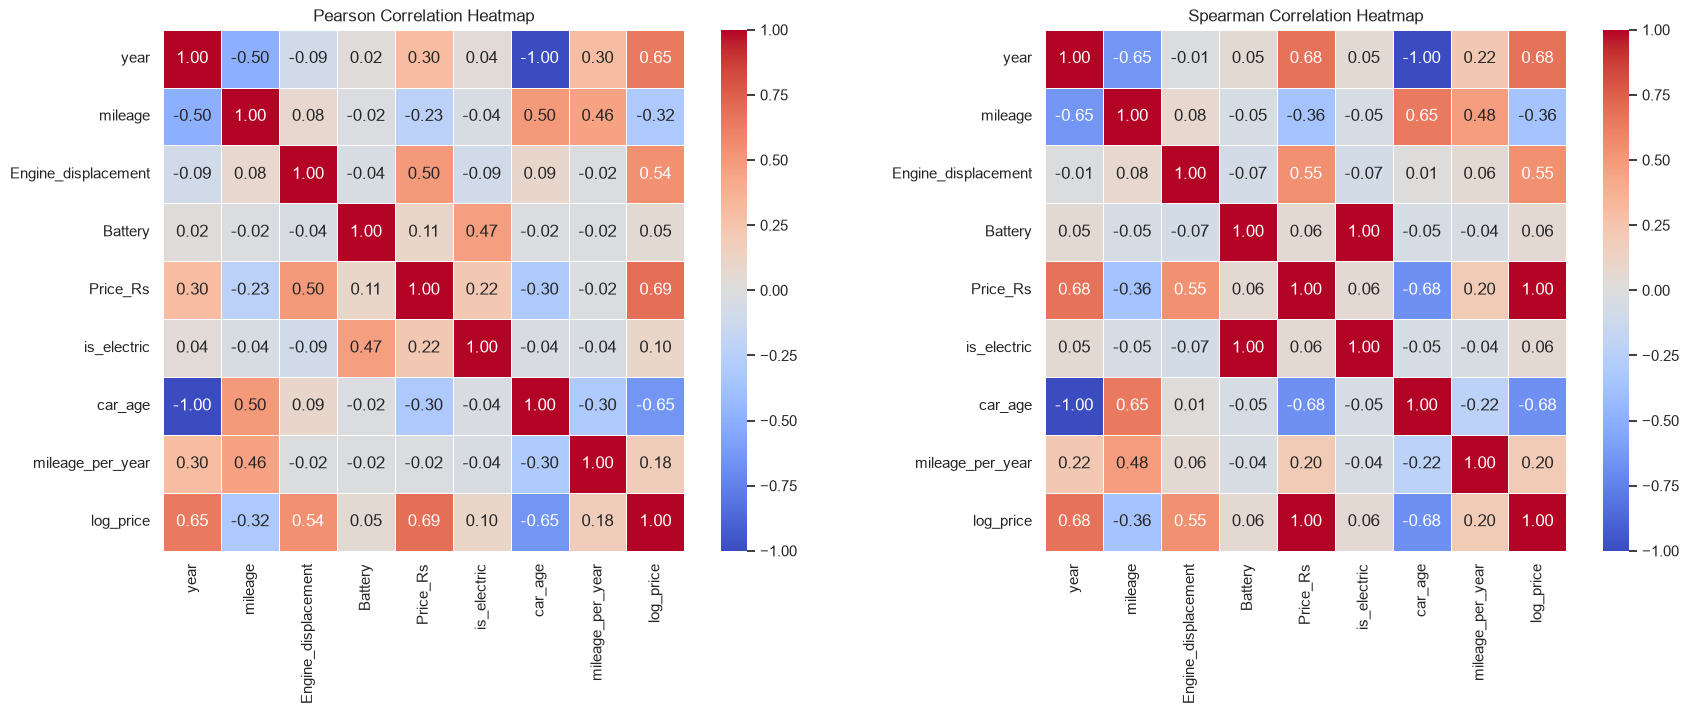


Feature pairs with |r| > 0.7:
feature_1 feature_2  pearson_r
     year   car_age       -1.0


In [33]:
# ---------- Batch D: Correlation analysis ----------
# Temporary frame for EDA only; log_price is NOT added to df, so it cannot leak into features
eda = df.select_dtypes(include="number").copy()
eda["log_price"] = np.log1p(df[TARGET])

pearson = eda.corr(method="pearson")
spearman = eda.corr(method="spearman")

print("Pearson correlation with Price_Rs:")
print(pearson[TARGET].drop(TARGET).sort_values(ascending=False).round(3).to_string())

print("\nSpearman correlation with Price_Rs:")
print(spearman[TARGET].drop(TARGET).sort_values(ascending=False).round(3).to_string())

fig, axes = plt.subplots(1, 2, figsize=(18, 7))
for ax, corr, name in zip(axes, [pearson, spearman], ["Pearson", "Spearman"]):
    sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0,
                vmin=-1, vmax=1, square=True, linewidths=0.5, ax=ax)
    ax.set_title(f"{name} Correlation Heatmap")
plt.tight_layout()
save_fig("D_correlation_heatmaps.png")
plt.show()

# Flag highly correlated feature pairs (potential redundancy)
feat_corr = pearson.drop(index=[TARGET, "log_price"], columns=[TARGET, "log_price"])
pairs = (feat_corr.where(np.triu(np.ones(feat_corr.shape), k=1).astype(bool))
                  .stack().reset_index())
pairs.columns = ["feature_1", "feature_2", "pearson_r"]
print("\nFeature pairs with |r| > 0.7:")
print(pairs[pairs["pearson_r"].abs() > 0.7].sort_values("pearson_r", key=abs, ascending=False).to_string(index=False))

In [34]:
# ---------- Batch E: Data-quality checks (read-only, nothing is changed) ----------
print("1) Most common mileage values:")
print(df["mileage"].value_counts().head(12).to_string())
print("\nmileage >= 500,000:", (df["mileage"] >= 500_000).sum())
print("mileage == 1,000,000:", (df["mileage"] == 1_000_000).sum())

print("\n2) Kilometres per year:")
for t in [30_000, 40_000, 50_000]:
    print(f"  mileage_per_year > {t:,}: {(df['mileage_per_year'] > t).sum()}")

print("\n3) Very low mileage on cars that are not new (mileage <= 100 and car_age >= 3):")
low = df[(df["mileage"] <= 100) & (df["car_age"] >= 3)]
print("  rows:", len(low))
print(low[["make", "model", "year", "mileage", "Price_Rs"]].head(8).to_string())

print("\n4) Engine displacement below 600 cc (value counts):")
print(df.loc[df["Engine_displacement"] < 600, "Engine_displacement"].value_counts().sort_index().to_string())

print("\n5) Cars older than 1970:", (df["year"] < 1970).sum())
print(df[df["year"] < 1970][["make", "model", "year", "mileage", "Price_Rs"]].to_string())

print("\n6) Price compared with the median of the same make/model/year (groups with 5+ listings):")
grp = df.groupby(["make", "model", "year"])[TARGET]
chk = df.assign(peer_median=grp.transform("median"),
                peer_count=grp.transform("count"))
chk = chk[chk["peer_count"] >= 5].copy()
chk["ratio"] = chk[TARGET] / chk["peer_median"]
print("  listings checked:", len(chk))
print("  price > 5x peer median:", (chk["ratio"] > 5).sum(), "| price < 0.2x peer median:", (chk["ratio"] < 0.2).sum())
cols = ["make", "model", "year", "mileage", "Engine_displacement", "city", TARGET, "peer_median", "ratio"]
print("\n  Highest ratios:")
print(chk.nlargest(10, "ratio")[cols].to_string())
print("\n  Lowest ratios:")
print(chk.nsmallest(10, "ratio")[cols].to_string())

print("\n7) Electric cars by make:")
print(df[df["is_electric"] == 1].groupby("make")[TARGET].agg(["count", "median"]).sort_values("count", ascending=False).head(10).to_string())

1) Most common mileage values:
mileage
100000.0    3520
150000.0    1995
200000.0    1612
80000.0     1333
90000.0     1076
120000.0     999
50000.0      987
70000.0      950
85000.0      816
60000.0      778
75000.0      752
65000.0      745

mileage >= 500,000: 0
mileage == 1,000,000: 0

2) Kilometres per year:
  mileage_per_year > 30,000: 333
  mileage_per_year > 40,000: 52
  mileage_per_year > 50,000: 0

3) Very low mileage on cars that are not new (mileage <= 100 and car_age >= 3):
  rows: 0
Empty DataFrame
Columns: [make, model, year, mileage, Price_Rs]
Index: []

4) Engine displacement below 600 cc (value counts):
Engine_displacement
0.0      127
500.0      2
539.0      1
549.0      1
596.0      1

5) Cars older than 1970: 64
             make      model  year   mileage  Price_Rs
1876       Toyota     Corona  1968  100000.0   1200000
2925         Jeep         CJ  1969  100000.0   2400000
3136         Jeep         CJ  1964    2800.0    150000
7190         Jeep         CJ  1960  1

## Train/Test Split, Preprocessing and Baseline
We split the data 70/30 first, then learn every preprocessing statistic (medians for imputation, target encodings, scaling) from the training set only, to avoid data leakage. All of this is wrapped in a scikit-learn pipeline, so it is refit correctly inside each cross-validation fold later. A mean-price baseline gives the reference that the real models must beat.

In [36]:
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.metrics import (mean_absolute_error, mean_squared_error,
                             r2_score, mean_absolute_percentage_error)
from sklearn.model_selection import KFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, TargetEncoder

RANDOM_STATE = 42

# ---------- 1) Features ----------
# Flags for missing values (row-level, so they cannot leak information between rows)
df["mileage_missing"] = df["mileage"].isna().astype(int)
df["engine_missing"] = df["Engine_displacement"].isna().astype(int)

CAT = ["make", "model", "city"]
NUM = ["car_age", "mileage", "Engine_displacement", "Battery", "is_electric",
       "mileage_missing", "engine_missing"]
# `year` is left out because it is the mirror image of car_age.
# mileage_per_year is recomputed inside the pipeline after imputation.
FEATURES = CAT + NUM

X = df[FEATURES].copy()
X[CAT] = X[CAT].astype(object)
y = df[TARGET]
y_log = np.log1p(y)

# ---------- 2) 70/30 split, stratified on price deciles ----------
price_bins = pd.qcut(y, 10, labels=False)
X_train, X_test, y_train, y_test, ylog_train, ylog_test = train_test_split(
    X, y, y_log, test_size=0.30, random_state=RANDOM_STATE, stratify=price_bins)

print(f"Train: {len(X_train):,} rows | Test: {len(X_test):,} rows")
print(f"Mean price  train: {y_train.mean():,.0f} | test: {y_test.mean():,.0f}")
print(f"Median price train: {y_train.median():,.0f} | test: {y_test.median():,.0f}")
print(f"Electric cars  train: {X_train['is_electric'].sum()} | test: {X_test['is_electric'].sum()}")

# ---------- 3) Preprocessing ----------
class CarFeatures(BaseEstimator, TransformerMixin):
    """Fill missing mileage/engine with TRAINING medians, then recompute mileage_per_year."""
    def fit(self, X, y=None):
        self.mileage_median_ = X["mileage"].median()
        self.engine_median_ = X["Engine_displacement"].median()
        return self

    def transform(self, X):
        X = X.copy()
        X["mileage"] = X["mileage"].fillna(self.mileage_median_)
        X["Engine_displacement"] = X["Engine_displacement"].fillna(self.engine_median_)
        X["mileage_per_year"] = X["mileage"] / X["car_age"]
        return X

NUM_ALL = NUM + ["mileage_per_year"]

def make_pipeline(model, scale=False):
    """Imputation -> target encoding of make/model/city -> (optional scaling) -> model."""
    prep = ColumnTransformer([
        ("cat", TargetEncoder(target_type="continuous", smooth="auto",
                        cv=KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)), CAT),
        ("num", StandardScaler() if scale else "passthrough", NUM_ALL),
    ])
    return Pipeline([("fix", CarFeatures()), ("prep", prep), ("model", model)])

# Sanity check: fit on train only, apply to both sets, look for leftover NaNs
check = make_pipeline(DummyRegressor(), scale=True)
Xtr = check[:-1].fit_transform(X_train, ylog_train)
Xte = check[:-1].transform(X_test)
print(f"\nTransformed shapes: train {Xtr.shape}, test {Xte.shape}")
print("NaNs left: train", int(np.isnan(Xtr).sum()), "| test", int(np.isnan(Xte).sum()))
print("Training medians used:", {"mileage": check["fix"].mileage_median_,
                                 "engine": check["fix"].engine_median_})

# ---------- 4) Evaluation helper ----------
def evaluate(y_true, y_pred):
    return {"MAE": mean_absolute_error(y_true, y_pred),
            "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
            "R2": r2_score(y_true, y_pred),
            "MAPE_%": mean_absolute_percentage_error(y_true, y_pred) * 100}

# ---------- 5) Baseline: always predict the training mean price ----------
baseline = DummyRegressor(strategy="mean").fit(X_train, y_train)
results = {"Baseline (mean price)": evaluate(y_test, baseline.predict(X_test))}
print("\nBaseline results on the test set (Rs):")
print(pd.DataFrame(results).T.round(2).to_string())

Train: 54,543 rows | Test: 23,376 rows
Mean price  train: 3,891,813 | test: 3,939,263
Median price train: 2,690,000 | test: 2,690,000
Electric cars  train: 83 | test: 44

Transformed shapes: train (54543, 11), test (23376, 11)
NaNs left: train 0 | test 0
Training medians used: {'mileage': np.float64(80000.0), 'engine': np.float64(1300.0)}

Baseline results on the test set (Rs):
                              MAE        RMSE   R2  MAPE_%
Baseline (mean price)  2680772.82  5952348.32 -0.0  144.59
